In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Insight Hunters - Data Preprocessing
# Project Setup & Environment Verification

from pathlib import Path
import os
import random
import numpy as np
import pandas as pd

# Reproducibility

RANDOM_SEED = 42

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# Project Paths

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Insight_Hunters_Project"
)

DATASETS_DIR = PROJECT_ROOT / "01_Datasets"
RAW_DIR = DATASETS_DIR / "Raw"
METADATA_DIR = DATASETS_DIR / "Metadata"
PROCESSED_DIR = DATASETS_DIR / "Processed"

SPLITS_DIR = PROJECT_ROOT / "02_Data_Splits"

TRAIN_DIR = SPLITS_DIR / "train"
VAL_DIR = SPLITS_DIR / "val"
TEST_DIR = SPLITS_DIR / "test"

CHECKPOINT_DIR = PROJECT_ROOT / "03_Model_Checkpoints"
RESULTS_DIR = PROJECT_ROOT / "04_Results"
EXPORTS_DIR = PROJECT_ROOT / "05_Exports"
NOTEBOOKS_DIR = PROJECT_ROOT / "06_Notebooks"


# Required Project Directories

required_directories = {
    "Project Root": PROJECT_ROOT,
    "Datasets": DATASETS_DIR,
    "Raw Data": RAW_DIR,
    "Metadata": METADATA_DIR,
    "Processed Data": PROCESSED_DIR,
    "Data Splits": SPLITS_DIR,
    "Training Split": TRAIN_DIR,
    "Validation Split": VAL_DIR,
    "Testing Split": TEST_DIR,
    "Model Checkpoints": CHECKPOINT_DIR,
    "Results": RESULTS_DIR,
    "Exports": EXPORTS_DIR,
    "Notebooks": NOTEBOOKS_DIR,
}


print("=" * 70)
print("PROJECT ENVIRONMENT VERIFICATION")
print("=" * 70)

all_directories_found = True

for name, path in required_directories.items():

    exists = path.exists()

    print(
        f"{'✓' if exists else '✗'} "
        f"{name:<20} -> {path}"
    )

    if not exists:
        all_directories_found = False


assert all_directories_found, (
    "One or more required project directories could not be found."
)

print("\n✓ All required project directories found.")


# Verifying the split class folders

EXPECTED_CLASSES = [
    "tb_negative",
    "tb_positive"
]

print("\n" + "=" * 70)
print("SPLIT CLASS FOLDER VERIFICATION")
print("=" * 70)

split_paths = {
    "train": TRAIN_DIR,
    "val": VAL_DIR,
    "test": TEST_DIR
}

for split_name, split_path in split_paths.items():

    class_folders = sorted([
        folder.name
        for folder in split_path.iterdir()
        if folder.is_dir()
    ])

    print(
        f"\n{split_name.upper()}: "
        f"{class_folders}"
    )

    assert class_folders == EXPECTED_CLASSES, (
        f"Unexpected class folders in {split_name}: "
        f"{class_folders}"
    )


print(
    "\n✓ Correct class folders found "
    "for train, validation and test."
)


# Verifying the metadata files

required_metadata = {
    "Split Manifest":
        METADATA_DIR / "split_manifest.csv",

    "Verified Split Summary":
        METADATA_DIR / "split_summary_verified.csv"
}


print("\n" + "=" * 70)
print("METADATA VERIFICATION")
print("=" * 70)

for name, path in required_metadata.items():

    exists = path.exists()

    print(
        f"{'✓' if exists else '✗'} "
        f"{name:<25} -> {path.name}"
    )

    assert exists, (
        f"Required metadata file missing: {path}"
    )


print(
    "\n✓ Required verified split metadata found."
)


# Creating the future output directories

output_directories = [
    RESULTS_DIR / "Metrics",
    RESULTS_DIR / "Confusion_Matrices",
    RESULTS_DIR / "Training_History",
    RESULTS_DIR / "Model_Comparison"
]

for directory in output_directories:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )


print("\n" + "=" * 70)
print("OUTPUT DIRECTORY SETUP")
print("=" * 70)

for directory in output_directories:
    print(
        f"✓ {directory.name}"
    )

# The final status

print("\n" + "=" * 70)
print("PROJECT SETUP VERIFIED")
print("=" * 70)

print("""
Project structure:       READY
Raw datasets:            ACCESSIBLE
Train split:             ACCESSIBLE
Validation split:        ACCESSIBLE
Test split:              ACCESSIBLE
Split manifest:          FOUND
Verified split summary:  FOUND
Model checkpoint folder: READY
Results folder:          READY
Export folder:           READY
Notebook folder:         READY
""")

print("=" * 70)
print("ENVIRONMENT CHECK PASSED")
print("=" * 70)

PROJECT ENVIRONMENT VERIFICATION
✓ Project Root         -> /content/drive/MyDrive/Insight_Hunters_Project
✓ Datasets             -> /content/drive/MyDrive/Insight_Hunters_Project/01_Datasets
✓ Raw Data             -> /content/drive/MyDrive/Insight_Hunters_Project/01_Datasets/Raw
✓ Metadata             -> /content/drive/MyDrive/Insight_Hunters_Project/01_Datasets/Metadata
✓ Processed Data       -> /content/drive/MyDrive/Insight_Hunters_Project/01_Datasets/Processed
✓ Data Splits          -> /content/drive/MyDrive/Insight_Hunters_Project/02_Data_Splits
✓ Training Split       -> /content/drive/MyDrive/Insight_Hunters_Project/02_Data_Splits/train
✓ Validation Split     -> /content/drive/MyDrive/Insight_Hunters_Project/02_Data_Splits/val
✓ Testing Split        -> /content/drive/MyDrive/Insight_Hunters_Project/02_Data_Splits/test
✓ Model Checkpoints    -> /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints
✓ Results              -> /content/drive/MyDrive/Insight_Hunters_Proje

In [ ]:
# Physical data split verification

from collections import Counter

print("=" * 70)
print("PHYSICAL DATA SPLIT VERIFICATION")
print("=" * 70)

IMAGE_EXTENSIONS = {
    ".png",
    ".jpg",
    ".jpeg"
}

expected_counts = {
    "train": {
        "tb_negative": 284,
        "tb_positive": 276,
        "total": 560
    },

    "val": {
        "tb_negative": 61,
        "tb_positive": 59,
        "total": 120
    },

    "test": {
        "tb_negative": 61,
        "tb_positive": 59,
        "total": 120
    }
}


physical_files = {}

for split_name, split_path in split_paths.items():

    physical_files[split_name] = {}

    print(
        f"\n{split_name.upper()}"
    )

    split_total = 0

    for class_name in EXPECTED_CLASSES:

        class_path = (
            split_path
            / class_name
        )

        files = sorted([
            file
            for file in class_path.iterdir()

            if (
                file.is_file()
                and
                file.suffix.lower()
                in IMAGE_EXTENSIONS
            )
        ])

        physical_files[
            split_name
        ][class_name] = files

        count = len(files)

        split_total += count

        print(
            f"  {class_name:<15}: "
            f"{count}"
        )

        assert count == (
            expected_counts[
                split_name
            ][class_name]
        ), (
            f"Unexpected number of images in "
            f"{split_name}/{class_name}. "
            f"Expected "
            f"{expected_counts[split_name][class_name]}, "
            f"found {count}."
        )

    print(
        f"  {'TOTAL':<15}: "
        f"{split_total}"
    )

    assert split_total == (
        expected_counts[
            split_name
        ]["total"]
    )


# Verifying the grand total

grand_total = sum(
    len(files)

    for split_data
    in physical_files.values()

    for files
    in split_data.values()
)

assert grand_total == 800


print("\n" + "=" * 70)
print("PHYSICAL IMAGE TOTAL")
print("=" * 70)

print(
    f"\nTotal physical split images: "
    f"{grand_total}"
)


# Checking the physical file overlap

split_filenames = {}

for split_name, class_data in physical_files.items():

    split_filenames[
        split_name
    ] = {

        file.name

        for files
        in class_data.values()

        for file
        in files
    }


train_val_overlap = (
    split_filenames["train"]
    &
    split_filenames["val"]
)

train_test_overlap = (
    split_filenames["train"]
    &
    split_filenames["test"]
)

val_test_overlap = (
    split_filenames["val"]
    &
    split_filenames["test"]
)


assert len(
    train_val_overlap
) == 0

assert len(
    train_test_overlap
) == 0

assert len(
    val_test_overlap
) == 0


print("\n" + "=" * 70)
print("PHYSICAL OVERLAP CHECK")
print("=" * 70)

print(
    f"\nTrain vs Validation: "
    f"{len(train_val_overlap)}"
)

print(
    f"Train vs Test:       "
    f"{len(train_test_overlap)}"
)

print(
    f"Validation vs Test:  "
    f"{len(val_test_overlap)}"
)


# Vetifying filename labels against class folders

incorrect_labels = []

for split_name, class_data in physical_files.items():

    for class_name, files in class_data.items():

        expected_suffix = (
            "_0"
            if class_name == "tb_negative"
            else "_1"
        )

        for file in files:

            if not file.stem.endswith(
                expected_suffix
            ):

                incorrect_labels.append(
                    {
                        "split": split_name,
                        "class_folder": class_name,
                        "filename": file.name
                    }
                )


assert len(
    incorrect_labels
) == 0, (
    f"{len(incorrect_labels)} files appear "
    f"to be stored in the wrong class folder."
)


print("\n" + "=" * 70)
print("FILENAME LABEL VERIFICATION")
print("=" * 70)

print(
    f"\nIncorrect class-folder "
    f"assignments detected: "
    f"{len(incorrect_labels)}"
)


# Final status

print("\n" + "=" * 70)
print("PHYSICAL DATA SPLIT VERIFIED")
print("=" * 70)

print(f"""
Training
--------
TB Negative: 284
TB Positive: 276
Total:       560

Validation
----------
TB Negative: 61
TB Positive: 59
Total:       120

Testing
-------
TB Negative: 61
TB Positive: 59
Total:       120

Complete dataset
----------------
TB Negative: 406
TB Positive: 394
Total:       {grand_total}

Physical overlap between splits: 0
Incorrect filename/class assignments: 0
""")

print("=" * 70)
print("ALL PHYSICAL SPLIT CHECKS PASSED")
print("=" * 70)

PHYSICAL DATA SPLIT VERIFICATION

TRAIN
  tb_negative    : 284
  tb_positive    : 276
  TOTAL          : 560

VAL
  tb_negative    : 61
  tb_positive    : 59
  TOTAL          : 120

TEST
  tb_negative    : 61
  tb_positive    : 59
  TOTAL          : 120

PHYSICAL IMAGE TOTAL

Total physical split images: 800

PHYSICAL OVERLAP CHECK

Train vs Validation: 0
Train vs Test:       0
Validation vs Test:  0

FILENAME LABEL VERIFICATION

Incorrect class-folder assignments detected: 0

PHYSICAL DATA SPLIT VERIFIED

Training
--------
TB Negative: 284
TB Positive: 276
Total:       560

Validation
----------
TB Negative: 61
TB Positive: 59
Total:       120

Testing
-------
TB Negative: 61
TB Positive: 59
Total:       120

Complete dataset
----------------
TB Negative: 406
TB Positive: 394
Total:       800

Physical overlap between splits: 0
Incorrect filename/class assignments: 0

ALL PHYSICAL SPLIT CHECKS PASSED


In [ ]:
# TensorFlow preprocessing configuration

import tensorflow as tf

# Reproducibility
tf.random.set_seed(RANDOM_SEED)

# Image pipeline configuration
IMG_HEIGHT = 224
IMG_WIDTH = 224
IMG_SIZE = (IMG_HEIGHT, IMG_WIDTH)

BATCH_SIZE = 32

CLASS_NAMES = [
    "tb_negative",
    "tb_positive"
]

# TensorFlow information
print("=" * 70)
print("TENSORFLOW CONFIGURATION")
print("=" * 70)

print(f"\nTensorFlow version: {tf.__version__}")
print(f"Image size:         {IMG_HEIGHT} x {IMG_WIDTH}")
print("Channels:           3 (RGB)")
print(f"Batch size:         {BATCH_SIZE}")
print(f"Random seed:        {RANDOM_SEED}")
print(f"Classes:            {CLASS_NAMES}")

# GPU availability
gpus = tf.config.list_physical_devices("GPU")

if gpus:
    print(f"\n✓ GPU detected: {len(gpus)} device(s)")

    for gpu in gpus:
        print(f"  - {gpu.name}")

else:
    print("\n⚠ No GPU detected.")
    print(
        "The preprocessing pipeline can still be tested, "
        "but GPU acceleration is recommended for model training."
    )

print("\n" + "=" * 70)
print("TENSORFLOW CONFIGURATION COMPLETE")
print("=" * 70)

TENSORFLOW CONFIGURATION

TensorFlow version: 2.20.0
Image size:         224 x 224
Channels:           3 (RGB)
Batch size:         32
Random seed:        42
Classes:            ['tb_negative', 'tb_positive']

⚠ No GPU detected.
The preprocessing pipeline can still be tested, but GPU acceleration is recommended for model training.

TENSORFLOW CONFIGURATION COMPLETE


In [ ]:
# Loading the training, validation, and test datasets

print("=" * 70)
print("LOADING TENSORFLOW DATASETS")
print("=" * 70)

# Loading the training data

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    labels="inferred",
    label_mode="binary",
    class_names=CLASS_NAMES,
    color_mode="rgb",
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE,
    shuffle=True,
    seed=RANDOM_SEED
)

# Loading the validation data

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    labels="inferred",
    label_mode="binary",
    class_names=CLASS_NAMES,
    color_mode="rgb",
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE,
    shuffle=False
)

# Loading the test data

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    labels="inferred",
    label_mode="binary",
    class_names=CLASS_NAMES,
    color_mode="rgb",
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE,
    shuffle=False
)

# Verifying the class order

print("\n" + "=" * 70)
print("CLASS MAPPING")
print("=" * 70)

print(f"\nClass 0 -> {CLASS_NAMES[0]}")
print(f"Class 1 -> {CLASS_NAMES[1]}")

assert train_ds.class_names == CLASS_NAMES
assert val_ds.class_names == CLASS_NAMES
assert test_ds.class_names == CLASS_NAMES

print("\n✓ Class mapping verified.")

# Verifying the batch structure

train_images, train_labels = next(iter(train_ds))
val_images, val_labels = next(iter(val_ds))
test_images, test_labels = next(iter(test_ds))

print("\n" + "=" * 70)
print("BATCH VERIFICATION")
print("=" * 70)

print(f"\nTraining image batch shape:   {train_images.shape}")
print(f"Training label batch shape:   {train_labels.shape}")

print(f"\nValidation image batch shape: {val_images.shape}")
print(f"Validation label batch shape: {val_labels.shape}")

print(f"\nTesting image batch shape:    {test_images.shape}")
print(f"Testing label batch shape:    {test_labels.shape}")

# Verifying the image dimensions
assert train_images.shape[1:] == (224, 224, 3)
assert val_images.shape[1:] == (224, 224, 3)
assert test_images.shape[1:] == (224, 224, 3)

# Verifying the binary labels
valid_labels = {0.0, 1.0}

assert set(
    np.unique(train_labels.numpy())
).issubset(valid_labels)

assert set(
    np.unique(val_labels.numpy())
).issubset(valid_labels)

assert set(
    np.unique(test_labels.numpy())
).issubset(valid_labels)

print("\n✓ Image dimensions verified: 224 × 224 × 3")
print("✓ Binary label structure verified.")

# Dataset batch counts

train_batches = tf.data.experimental.cardinality(
    train_ds
).numpy()

val_batches = tf.data.experimental.cardinality(
    val_ds
).numpy()

test_batches = tf.data.experimental.cardinality(
    test_ds
).numpy()

print("\n" + "=" * 70)
print("DATASET BATCH COUNTS")
print("=" * 70)

print(f"\nTraining batches:   {train_batches}")
print(f"Validation batches: {val_batches}")
print(f"Testing batches:    {test_batches}")

# Expected:
# ceil(560 / 32) = 18
# ceil(120 / 32) = 4
# ceil(120 / 32) = 4

assert train_batches == 18
assert val_batches == 4
assert test_batches == 4

# Final status

print("\n" + "=" * 70)
print("TENSORFLOW DATA LOADING VERIFIED")
print("=" * 70)

print("""
Training images:     560
Validation images:   120
Testing images:      120

Input dimensions:    224 x 224 x 3
Label mode:          Binary
Class 0:             TB Negative
Class 1:             TB Positive
Batch size:          32
""")

print("=" * 70)
print("MODEL-READY DATASETS CREATED SUCCESSFULLY")
print("=" * 70)

LOADING TENSORFLOW DATASETS
Found 560 files belonging to 2 classes.
Found 120 files belonging to 2 classes.
Found 120 files belonging to 2 classes.

CLASS MAPPING

Class 0 -> tb_negative
Class 1 -> tb_positive

✓ Class mapping verified.

BATCH VERIFICATION

Training image batch shape:   (32, 224, 224, 3)
Training label batch shape:   (32, 1)

Validation image batch shape: (32, 224, 224, 3)
Validation label batch shape: (32, 1)

Testing image batch shape:    (32, 224, 224, 3)
Testing label batch shape:    (32, 1)

✓ Image dimensions verified: 224 × 224 × 3
✓ Binary label structure verified.

DATASET BATCH COUNTS

Training batches:   18
Validation batches: 4
Testing batches:    4

TENSORFLOW DATA LOADING VERIFIED

Training images:     560
Validation images:   120
Testing images:      120

Input dimensions:    224 x 224 x 3
Label mode:          Binary
Class 0:             TB Negative
Class 1:             TB Positive
Batch size:          32

MODEL-READY DATASETS CREATED SUCCESSFULLY


MODEL-READY DATA SANITY CHECK

Pixel value minimum: 0.00
Pixel value maximum: 255.00

✓ Raw TensorFlow image values are within the expected 0-255 range.


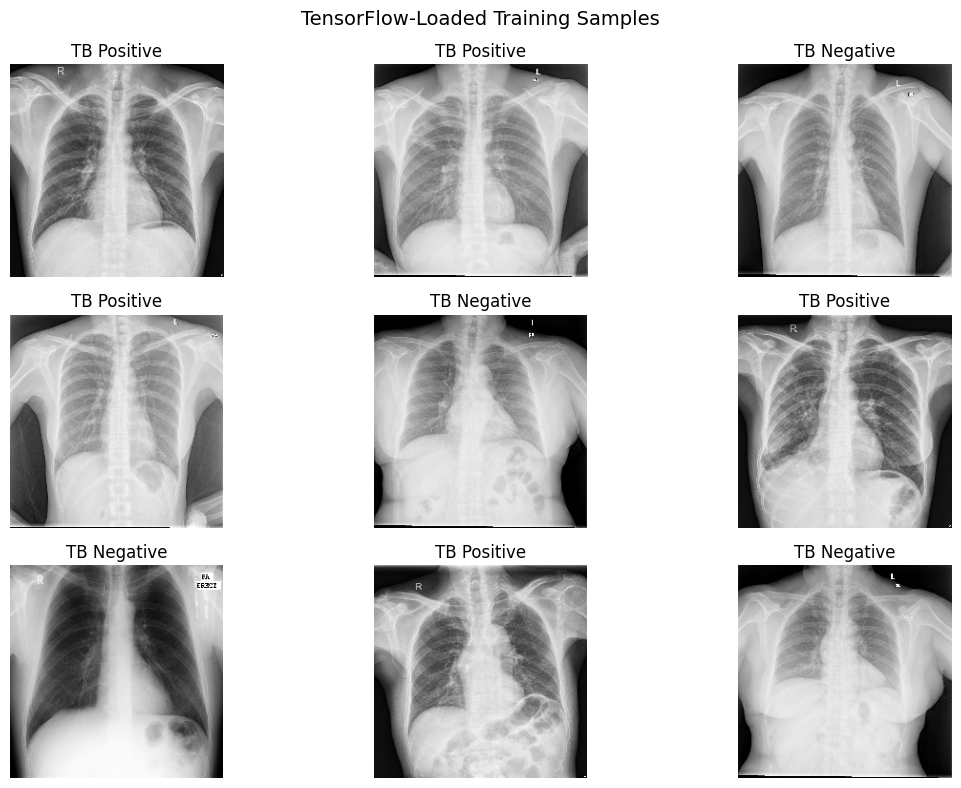


✓ Dataset prefetching enabled.

PREPROCESSING STRATEGY

Base input pipeline
-------------------
Image dimensions:     224 x 224
Channels:             RGB (3)
Labels:               Binary
Training shuffle:     Enabled
Validation shuffle:   Disabled
Testing shuffle:      Disabled
Prefetching:          Enabled

Important:
The base datasets retain pixel values in their loaded
0-255 representation.

Model-specific normalization/preprocessing will be
applied when each CNN architecture is constructed.

Data augmentation will be applied to TRAINING data only.
Validation and test images will not be augmented.

DATA PREPROCESSING PIPELINE VERIFIED


In [ ]:
# Checking the model ready data

import matplotlib.pyplot as plt

print("=" * 70)
print("MODEL-READY DATA SANITY CHECK")
print("=" * 70)

# Checking the pixel value range

sample_images, sample_labels = next(iter(train_ds))

pixel_min = float(
    tf.reduce_min(sample_images).numpy()
)

pixel_max = float(
    tf.reduce_max(sample_images).numpy()
)

print(f"\nPixel value minimum: {pixel_min:.2f}")
print(f"Pixel value maximum: {pixel_max:.2f}")

assert pixel_min >= 0.0
assert pixel_max <= 255.0

print(
    "\n✓ Raw TensorFlow image values "
    "are within the expected 0-255 range."
)


# Displaying the sample images

plt.figure(
    figsize=(12, 8)
)

for i in range(9):

    ax = plt.subplot(
        3,
        3,
        i + 1
    )

    plt.imshow(
        sample_images[i].numpy().astype("uint8")
    )

    label = int(
        sample_labels[i].numpy()[0]
    )

    plt.title(
        "TB Positive"
        if label == 1
        else "TB Negative"
    )

    plt.axis("off")


plt.suptitle(
    "TensorFlow-Loaded Training Samples",
    fontsize=14
)

plt.tight_layout()
plt.show()


# Optimising the pipeline

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(
    buffer_size=AUTOTUNE
)

val_ds = val_ds.prefetch(
    buffer_size=AUTOTUNE
)

test_ds = test_ds.prefetch(
    buffer_size=AUTOTUNE
)


print("\n✓ Dataset prefetching enabled.")


# Preprocessing strategy

print("\n" + "=" * 70)
print("PREPROCESSING STRATEGY")
print("=" * 70)

print("""
Base input pipeline
-------------------
Image dimensions:     224 x 224
Channels:             RGB (3)
Labels:               Binary
Training shuffle:     Enabled
Validation shuffle:   Disabled
Testing shuffle:      Disabled
Prefetching:          Enabled

Important:
The base datasets retain pixel values in their loaded
0-255 representation.

Model-specific normalization/preprocessing will be
applied when each CNN architecture is constructed.

Data augmentation will be applied to TRAINING data only.
Validation and test images will not be augmented.
""")


print("=" * 70)
print("DATA PREPROCESSING PIPELINE VERIFIED")
print("=" * 70)

In [ ]:
# The projects dependency verification

import sys
import numpy
import pandas
import matplotlib
import PIL
import sklearn
import tensorflow

print("=" * 70)
print("PROJECT DEPENDENCY VERIFICATION")
print("=" * 70)

dependencies = {
    "Python": sys.version.split()[0],
    "NumPy": numpy.__version__,
    "Pandas": pandas.__version__,
    "Matplotlib": matplotlib.__version__,
    "Pillow": PIL.__version__,
    "Scikit-learn": sklearn.__version__,
    "TensorFlow": tensorflow.__version__
}

for package, version in dependencies.items():
    print(f"{package:<15}: {version}")

print("\n✓ All core project dependencies imported successfully.")

print("\n" + "=" * 70)
print("DEPENDENCY CHECK PASSED")
print("=" * 70)

PROJECT DEPENDENCY VERIFICATION
Python         : 3.13.15
NumPy          : 2.1.3
Pandas         : 2.2.3
Matplotlib     : 3.10.0
Pillow         : 11.3.0
Scikit-learn   : 1.6.1
TensorFlow     : 2.20.0

✓ All core project dependencies imported successfully.

DEPENDENCY CHECK PASSED


In [ ]:
# Creating the requirements file for our project

requirements_path = PROJECT_ROOT / "requirements.txt"

requirements = f"""numpy=={numpy.__version__}
pandas=={pandas.__version__}
matplotlib=={matplotlib.__version__}
Pillow=={PIL.__version__}
scikit-learn=={sklearn.__version__}
tensorflow=={tensorflow.__version__}
"""

requirements_path.write_text(requirements)

print("=" * 70)
print("REQUIREMENTS FILE CREATED")
print("=" * 70)

print(f"\nSaved to:\n{requirements_path}")

print("\nContents:\n")
print(requirements)

assert requirements_path.exists()

print("=" * 70)
print("DEPENDENCY SETUP COMPLETE")
print("=" * 70)

REQUIREMENTS FILE CREATED

Saved to:
/content/drive/MyDrive/Insight_Hunters_Project/requirements.txt

Contents:

numpy==2.1.3
pandas==2.2.3
matplotlib==3.10.0
Pillow==11.3.0
scikit-learn==1.6.1
tensorflow==2.20.0

DEPENDENCY SETUP COMPLETE
